# FasterWAM on OpenVINO: convert and run a world-action model

[FasterWAM](https://huggingface.co/hustvl/FasterWAM) is a **world-action model** for robot manipulation.
Given one camera observation, a language instruction and the proprioceptive state of the arm, it
predicts the next chunk of 32 low-level actions: a translation, a rotation and a gripper command per
step.

This notebook shows how to use OpenVINO to convert and run FasterWAM. It takes the inference graph
apart into its three units, exports them to OpenVINO IR, compiles them for a CPU or GPU, and runs
the **complete** pipeline: one observation and one instruction in, one chunk of actions out. There is
one export decision left - `fp16` or INT8 weights - because the graph optimizations this project
promoted are always applied; the conversion section lists each of them with what it is worth and why
it is safe, so the graph that ships is the graph you can read about. Along the way it explains what
the model does at inference time - the video expert runs once per chunk and the action expert ten
times - and ends with an interactive section where you can change the observation, the instruction, the noise and
the sampling settings and watch the predicted actions change. The instruction really is an input: the
umT5-xxl text encoder is converted and run in this notebook, so text typed there is encoded on the spot.

It does not take the conversion on trust either: one section runs the **original PyTorch model on the
CPU** for the same inputs, and a later one compares the converted action chunk against it, per graph.

#### Requirements

| Peak memory | fp16 | INT8 (weight-only) |
|---|---|---|
| **CPU** - export (once) | about 56 GB | about 56 GB |
| **CPU** - inference (graphs + text encoder, f32) | about 54 GB | about 43 GB |
| **GPU** - export (once, runs on the CPU) | about 56 GB | about 56 GB |
| **GPU** - inference (graphs + text encoder, bf16) | about 19 GB | about 10 GB |

Export always runs on the CPU, whatever device you pick, and peaks while the video unit is
converted; the text encoder's conversion and the one-off PyTorch reference chunk stay below that.
Inference counts the three graphs and the text encoder loaded together; on a GPU, the optional INT8
text encoder saves about 5.7 GB more. Below about 64 GB of RAM, run the CPU with the INT8 graphs.

The first run also needs **network and disk**: it downloads about 28 GB - the repository clone, the
11.1 GB checkpoint, the 11.4 GB text encoder and 4.7 GB of LIBERO episodes - and holds about 75 GB at
the peak of the conversion, mostly the ONNX scratch and the IR itself. Later runs reuse all of it.

#### Table of contents:

- [Requirements](#Requirements)
- [Setup](#Setup)
- [The three graphs](#The-three-graphs)
- [Sample Inputs](#Sample-Inputs)
- [OpenVINO IR conversion](#OpenVINO-IR-conversion)
- [The text encoder](#The-text-encoder)
- [The PyTorch reference](#The-PyTorch-reference)
- [OpenVINO Inference](#OpenVINO-Inference)
- [Accuracy of the converted graph](#Accuracy-of-the-converted-graph)
- [Explore it interactively](#Explore-it-interactively)
- [Cleanup](#Cleanup)

The notebook fetches everything the export needs by itself: a shallow `git clone` of
[hustvl/FasterWAM](https://github.com/hustvl/FasterWAM) and the released LIBERO checkpoint from
[Hugging Face](https://huggingface.co/hustvl/FasterWAM), both into its own `model/` folder, which
also receives the exported IR. The notebook installs its own packages (including a CPU Torch for the
export subprocess and the reference run) into a notebook-local `.venv`.

### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/fasterWAM/fasterWAM.ipynb" />


In [1]:
import urllib.request
from pathlib import Path

# Helpers come from `utils` of the cloned repository, otherwise from GitHub; local copies are overwritten
helper_files = ["notebook_utils.py"]
repo_utils = Path("../../utils")
in_repo = (repo_utils / "notebook_utils.py").is_file()
if in_repo:
    helper_contents = {helper_file: (repo_utils / helper_file).read_bytes() for helper_file in helper_files}
else:
    try:
        helper_contents = {}
        for helper_file in helper_files:
            url = f"https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/{helper_file}"
            with urllib.request.urlopen(url, timeout=10) as response:
                helper_contents[helper_file] = response.read()
    except OSError as error:
        if any(not Path(helper_file).is_file() for helper_file in helper_files):
            raise
        print(f"Could not update helper files, using the existing copies: {error}")
        helper_contents = {}

for helper_file, content in helper_contents.items():
    Path(helper_file).write_bytes(content)

from notebook_utils import setup_notebook_venv

# Requirements installed below go to a notebook-specific virtual environment in the `.venv` folder
setup_notebook_venv()

Using virtual environment: /home/clee30/openvino_notebooks/notebooks/fasterWAM/.venv


PosixPath('/home/clee30/openvino_notebooks/notebooks/fasterWAM/.venv')

In [2]:
# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("fasterWAM.ipynb")

In [3]:
# Torch is needed only by the export subprocess; the CPU wheel keeps this light - inference is
# OpenVINO. The pins match the versions the FasterWAM repository locks (imageio and transformers
# are imported by its package at import time). Torch goes first so the installs below reuse it.
%pip install -q "torch==2.7.1" "torchvision==0.22.1" --index-url https://download.pytorch.org/whl/cpu
%pip install -q "matplotlib>=3.4" "ipywidgets>=8" "nncf>=2.13" "onnx>=1.16" "einops>=0.8" "hydra-core>=1.3" "omegaconf>=2.3" "huggingface_hub>=0.25" "imageio==2.37.0" "transformers==4.49.0" "accelerate==1.12.0" "boto3==1.35.99" "termcolor==2.5.0"
# Reading the LIBERO episodes (the sample-inputs cell) needs the parquet and packed-mp4
# readers, plus gitpython for the repository's normalizer import.
%pip install -q "pandas>=2.2" "pyarrow>=17" "av>=13" "gitpython==3.1.45"

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Setup

One thing has to be true before the first inference: OpenVINO has to be importable. Everything else
comes with the notebook or is built by it - the evaluation artifacts are generated in
[Sample Inputs](#Sample-Inputs), which checks every one of them, so that a failure later on is never
ambiguous.

The **configuration cell** below sets `STEPS` and the benchmark counts. The precision to convert is
chosen in [OpenVINO IR conversion](#OpenVINO-IR-conversion), right before the conversion, and the device to run on in
[OpenVINO Inference](#OpenVINO-Inference), right before compiling - neither costs more than re-running from there.

In [4]:
import importlib
import time
from pathlib import Path

import numpy as np
import openvino as ov
from IPython.display import Markdown, display

import fwam_ov

# Re-execute the local helper module so edits to fwam_ov.py are picked up by re-running
# this cell, instead of needing a kernel restart (1 ms, no module-level state to lose)
importlib.reload(fwam_ov)

# ------------------------------------------------------------------ configuration
STEPS = 10  # flow-matching Euler steps per chunk (the checkpoint was trained for 10)
NITER = 15  # timed chunks after the warmup; single chunks vary by +-10 ms, so use the p50
WARMUP = 3  # untimed chunks, so one-time kernel setup is not measured

try:
    import matplotlib.pyplot as plt

    %matplotlib inline
    HAVE_PLOTS = True
except ImportError:
    plt = None
    HAVE_PLOTS = False

print(f"openvino {ov.__version__} | numpy {np.__version__} | plots: {'on' if HAVE_PLOTS else 'off (text tables only)'}")

import ipywidgets as widgets

openvino 2026.5.1-23845-d528f86f1ce | numpy 2.4.6 | plots: on


In [5]:
NOTEBOOK_DIR = Path.cwd()  # everything the notebook creates lives next to it
MODEL_DIR = fwam_ov.model_dir(NOTEBOOK_DIR)  # source clone + checkpoint + exported IR sets

print(f"model folder : {MODEL_DIR} (source clone, checkpoint, exported IR)")
print(f"artifacts    : {NOTEBOOK_DIR / 'artifacts'} (evaluation inputs, generated on first use)")
print(f"free space   : {fwam_ov.free_gb(NOTEBOOK_DIR)} GB available to {NOTEBOOK_DIR}")

model folder : /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model (source clone, checkpoint, exported IR)
artifacts    : /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/artifacts (evaluation inputs, generated on first use)
free space   : 89.6 GB available to /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM


## The three graphs

One action chunk is not one network. FasterWAM is a Mixture-of-Transformers: a large **video expert**
that reads the observation and the instruction, and a small **action expert** that denoises the
action chunk. The video expert runs **once** per chunk; the action expert runs **ten** times, once
per Euler step. That asymmetry is what the export exploits, and it is why the pipeline is split
along these three boundaries:

| # | graph | inputs | output | runs per chunk |
|---|-------|--------|--------|----------------|
| 1 | `vae` | `image [1,3,1,224,448]` | `latent [1,48,1,14,28]` | 1 |
| 2 | `video` | `latents [1,48,3,14,28]`, `timestep [1]`, `context [1,129,4096]`, `context_mask [1,129]` | **16 fused K/V** tensors `[1,294,3072]` | 1 |
| 3 | `action` | `latents_action [1,32,7]`, `t [1]`, `context [1,129,4096]`, the same 16 K/V | `pred [1,32,7]` | **10** |

Two details are worth pausing on, because they explain most of the performance story.

The video graph is **not a video generator here**. It taps the key/value tensors of every fourth of
its 30 blocks (blocks 0, 4, 8, ... 28, that is 8 layers, that is 16 tensors) and returns them. One
forward pass therefore produces exactly the conditioning the action expert needs. Rendering a
predicted video would need a full denoising loop plus a VAE decoder; policy inference needs neither.

The 16 K/V tensors and the context are **constant across the ten action steps**; only
`latents_action` and `t` change. They are therefore cast to the action graph's precision once per
chunk and, where the device allows it, kept in device memory instead of being re-fed from the host -
the lever the shipped pipeline pulls hardest.

## Sample Inputs

The evaluation artifacts hold 32 LIBERO episodes. Each sample holds the observation as a
**dual-camera mosaic** — the third-person `agentview` camera on the left half, the wrist camera on
the right half — plus the normalized proprioceptive state, the ground-truth action chunk and the
umT5 text context of its instruction.

The packs are not committed with the notebook: the cell below generates them, and downloads the
LIBERO episodes they are built from
([`yuanty/LIBERO-fastwam`](https://huggingface.co/datasets/yuanty/LIBERO-fastwam), CC BY 4.0), once.
Both are reused afterwards.

In [6]:
# The evaluation packs are generated on first use (the artifacts/ folder is not committed). Four of
# the five steps run on this machine from the released checkpoint and the umT5 weights - the seeded
# noise, the proprio projection, the 32 umT5 contexts, and the runtime pack plus the PyTorch
# reference for it. The observations are the real LIBERO episodes, which the generator downloads on
# this first run (4.7 GB from Hugging Face) and reuses afterwards. Everything runs in a subprocess, so
# this kernel still never imports torch. Without a network, or with a copy of the episodes already on
# disk, call fwam_ov.ensure_eval_artifacts(NOTEBOOK_DIR) after `make_eval_packs.py --no-download` /
# `--data-root <path>` instead - the generator takes both flags.
CLONE = fwam_ov.clone_source(NOTEBOOK_DIR)  # reused by the export section below
CHECKPOINT = fwam_ov.download_checkpoint(NOTEBOOK_DIR)
eval_packs = fwam_ov.ensure_eval_artifacts(NOTEBOOK_DIR)
ARTIFACTS = fwam_ov.artifacts_dir(NOTEBOOK_DIR)  # every file present, or FileNotFoundError
print()
print(f"artifacts: {eval_packs['source']} in {eval_packs['seconds']:.0f} s -> {ARTIFACTS}")
for name, path in eval_packs["paths"].items():
    print(f"  {name:22s} {path.stat().st_size / 1e6:7.2f} MB")

[src] fetching https://github.com/hustvl/FasterWAM.git @ 8366781 into /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM ...
[src] cloned into /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM
[ckpt] downloading hustvl/FasterWAM@6bf9471 (libero/*) into /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM/checkpoints ...


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

libero/step_021700.pt:   0%|          | 0.00/11.1G [00:00<?, ?B/s]

dataset_stats.json: 0.00B [00:00, ?B/s]

[ckpt] /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM/checkpoints/hustvl/FasterWAM/libero/step_021700.pt (11.12 GB)
[packs] generating the evaluation artifacts in /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/artifacts (6 of 6 missing: eval_contexts.npz, eval_latents.npz, eval_proprio.npz, eval_samples.json, eval_samples.npz, ov_runtime_pack.npz)
[packs] four of the five steps only need the checkpoint and umT5; the observations come from the LIBERO episodes (see this cell's output if they are absent)
[packs] steps ['samples', 'proprio', 'contexts', 'latents', 'pack'] -> /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/artifacts (reuse what exists)
[samples] the LIBERO episodes are not under /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM/data/libero_mujoco3.3.2_raw/lerobot_v30 - fetching yuanty/LIBERO-fastwam from Hugging Face (4.7 GB of packed mp4s and parquet, the unpacked lerobot_v30 tree; the tarballs are

In [7]:
tasks = fwam_ov.eval_tasks(ARTIFACTS)
print(f"{len(tasks)} samples, {len(set(tasks))} distinct instructions")
for index in range(3):
    print(f"  [{index}] {tasks[index][:96]}")

32 samples, 32 distinct instructions
  [0] pick up the black bowl between the plate and the ramekin and place it on the plate
  [1] pick up the black bowl from table center and place it on the plate
  [2] pick up the black bowl in the top drawer of the wooden cabinet and place it on the plate


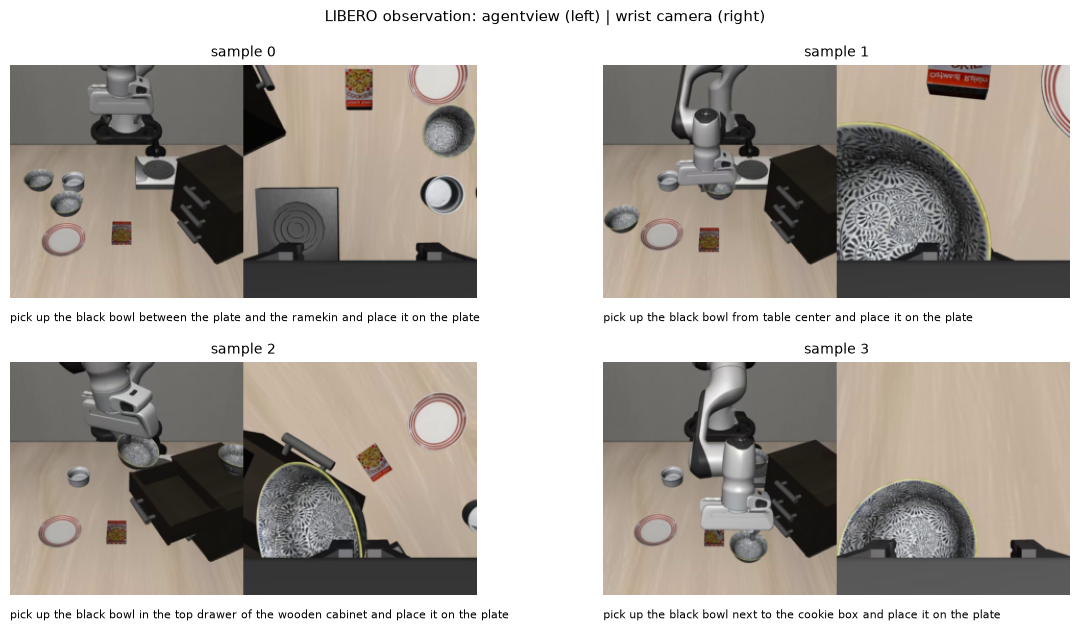

In [8]:
import textwrap

gallery = [fwam_ov.eval_inputs(ARTIFACTS, index) for index in range(4)]

if HAVE_PLOTS:
    figure, axes = plt.subplots(2, 2, figsize=(11, 6.4))
    for index, (axis, sample) in enumerate(zip(axes.ravel(), gallery)):
        axis.imshow(sample["image_hwc"])
        axis.set_title(f"sample {index}", fontsize=10)
        axis.axis("off")
        axis.text(0.0, -0.06, "\n".join(textwrap.wrap(tasks[index], 88)), transform=axis.transAxes, fontsize=8, va="top")
    figure.suptitle("LIBERO observation: agentview (left) | wrist camera (right)", fontsize=11)
    figure.tight_layout()
    plt.show()
else:
    print("matplotlib is not available; sample 0 image shape:", gallery[0]["image_hwc"].shape)

ground-truth action chunk: (32, 7) dtype float32


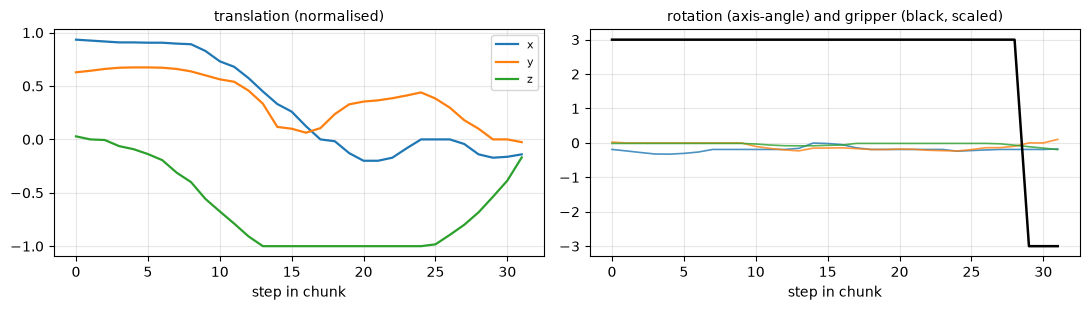

In [9]:
gt = gallery[0]["gt_action"]  # [32, 7]: translation xyz, rotation axis-angle, gripper
print("ground-truth action chunk:", gt.shape, "dtype", gt.dtype)

if HAVE_PLOTS:
    figure, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].plot(gt[:, :3], lw=1.6)
    axes[0].set_title("translation (normalized)", fontsize=10)
    axes[0].legend(["x", "y", "z"], fontsize=8)
    axes[1].plot(gt[:, 3:6], lw=1.2, alpha=0.8)
    axes[1].plot(gt[:, 6] * 3.0, lw=1.8, color="black")
    axes[1].set_title("rotation (axis-angle) and gripper (black, scaled)", fontsize=10)
    for axis in axes:
        axis.set_xlabel("step in chunk")
        axis.grid(alpha=0.3)
    figure.tight_layout()
    plt.show()

## OpenVINO IR conversion

The cells below turn the checkpoint into OpenVINO IR. One thing is chosen first: the **weight
compression**, `fp16` (the default, about 10.6 GB of IR) or `int8` (weight-only NNCF `INT8_SYM` on the
video and action experts, about 5.4 GB).

Everything else about the graph is fixed. The export always applies every optimization this project
promoted - the default export *is* the shipped graph - so there is no panel of switches here to get
into the wrong state. The levers are listed anyway, because they are what makes this IR fast, and
because each one keeps its own exporter flag: a rollback is that flag and a re-export outside this
notebook (`--rope2 0`), and the code that implements each of them is a named monkeypatch in the
bundled exporter under `utils/fwam_export/`, which treats the cloned repository as read-only.

| lever (exporter flag) | what changes in the graph | measured |
|---|---|---|
| **RoPE-3** (`--rope3`) | RoPE in the half-major (GPT-NeoX) basis, fused into one kernel; re-bases the q/k weights of every self-attention, so video and action must come from the same set | about 1.5 % of a chunk |
| **RoPE-2** (`--rope2`) | pair-swap-free RoPE: 3 kernels per application instead of 9, bit-identical result; only takes effect with RoPE-3 off, which already contains it | about 1 % of a chunk |
| **t_mod M=2** (`--tmod2`) | the video timestep embedding is built from its 2 real timesteps instead of all 294 | under 0.5 % of a chunk |
| **t_mod per frame** (`--modg`) | broadcasts t_mod once per latent frame, so the 29 per-block modulation adds run on `[1,3,6,64]` instead of `[1,294,6,3072]` and the 176 per-token modulation crops disappear; needs t_mod M=2 | about 6 % of a chunk |
| **VAE depth fold** (`--vae-fold`) | the encoder's Conv3D `kd=3` only ever sees a depth-1 tensor, so 22 of its 66 taps are dead: 233 -> 81 GMAC | about 6 % of a chunk; weights 296 -> 108 MB |

The first four levers were measured one at a time on a discrete GPU; the VAE fold was re-measured on
an integrated GPU, where it is worth the most. Measured as a group on that integrated GPU, at identical
runtime settings, the promoted graph is **13.6 % faster per chunk** than the graph from before them -
most of it in the ten action steps, because the action expert pays the RoPE and timestep-embedding cost
ten times per chunk. The INT8 weights then take about **a third** off the chunk on top of that. The
shares are what the export buys; the absolute times depend on the device you run on.

Then the two steps:

1. **Fetch** - a shallow `git clone` of the [FasterWAM repository](https://github.com/hustvl/FasterWAM)
   into `<notebook>/model/FasterWAM`, plus the released LIBERO checkpoint from
   [Hugging Face](https://huggingface.co/hustvl/FasterWAM) into that clone's `checkpoints/`. Both
   are reused when already present; the checkpoint is the sole source of weights (`skip_dit_load_from_pretrain`),
   so no Wan2.2 components are downloaded.
2. **Convert** - the exporter bundled in this notebook's `utils/fwam_export` traces the three units
   from the clone through Torch -> ONNX -> OpenVINO IR (with the INT8 option, NNCF weight-only compression
   is applied on top).

The converted set is kept. A complete set for the chosen precision is reused on later runs and never
deleted or overwritten: it lives in `model/ir/fp16/` or `model/ir/int8/`, one directory per unit
(`vae/`, `video/`, `action/`, `t5/`) and no deeper. Delete that directory to re-export - note that the
precision directory also holds the text encoder, so that goes with it. The notebook only ever compiles
what it exported itself.

Conversion is the slow part - the video graph alone is a 9.4 GB IR and takes minutes, and the whole
set needs the memory listed under [Requirements](#Requirements). It is also why Torch is
installed in the notebook environment but never imported by this kernel: the exporter runs as a
subprocess, and inference needs nothing but OpenVINO.

Everything after the conversion runs on the one set you converted.


In [10]:
# Source and checkpoint: cloned/downloaded once, reused on later runs.
CLONE = fwam_ov.clone_source(NOTEBOOK_DIR)
CHECKPOINT = fwam_ov.download_checkpoint(NOTEBOOK_DIR)

[src] reusing the FasterWAM clone at /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM (commit 8366781)
[ckpt] reusing /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM/checkpoints/hustvl/FasterWAM/libero/step_021700.pt (11.12 GB)


In [11]:
# The one export decision: how the weights are stored. The graph is not a choice - the fully
# promoted set from the table above is what gets exported, in both precisions.
PRECISION = widgets.Dropdown(
    options=[("fp16", "fp16"), ("int8 - NNCF weight-only INT8_SYM", "int8")],
    value="fp16",
    description="Convert to:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="auto"),
)
PRECISION_INFO = {
    "fp16": "fp16: full half-precision weights, about 10.6 GB of IR.",
    "int8": "int8: symmetric weight-only INT8_SYM (NNCF), ratio 1.0, per-channel (group_size -1), "
    "data-free, applied to the video and action experts; about 5.4 GB of IR and about "
    "110 ms per chunk faster on an integrated GPU.",
}
precision_note = widgets.HTML()


def _show_precision(change=None):
    precision_note.value = f"<i>{PRECISION_INFO[PRECISION.value]}</i>"


PRECISION.observe(_show_precision, names="value")
_show_precision()
display(widgets.HBox([PRECISION, precision_note]))

In [13]:
# What the export is, in full. There is nothing to configure here, so the cell prints the exporter
# command it is about to run and then converts - or reuses the set if this precision is already on
# disk. `--dtype` is the *trace* dtype, fp16 either way; the precision picked above shows up as
# --video-int8 / --action-int8 / --trace-half (weight-only INT8 on top of the same fp16 trace).
chosen = PRECISION.value
deviation = {k: v for k, v in fwam_ov.export_deltas().items() if v != "default"}
assert not deviation, f"the notebook exports the promoted graph; these flags deviate: {deviation}"

print("graph   : fully promoted (every row of the table above, in both precisions)")
for unit, argv in fwam_ov.export_plan(chosen, NOTEBOOK_DIR).items():
    keep, skip = [], False
    for token in argv[2:]:  # drop the interpreter and the exporter path
        if skip:
            skip = False
        elif token in ("--out-dir", "--ref"):
            skip = True
        else:
            keep.append(token)
    print(f"  {unit:6s} " + " ".join(keep))
print()

ir_set = fwam_ov.ensure_ir(chosen, NOTEBOOK_DIR)
print()
print(f"{chosen} source : {ir_set['source']}")
print(f"{chosen} size   : {fwam_ov.ir_size_mb(ir_set['paths'])} MB")
for unit, path in ir_set["paths"].items():
    print(f"  {unit:6s} {path}")

RUN_PRECISION = chosen  # the precision every cell below compiles, infers and reports
print(f"\nrunning : {RUN_PRECISION}")

graph   : fully promoted (every row of the table above, in both precisions)
  vae    --unit vae --dtype fp16 --rope2 1 --rope3 1 --tmod2 1 --modg 1 --vae-fold --reuse-ref
  video  --unit video --dtype fp16 --rope2 1 --rope3 1 --tmod2 1 --modg 1 --vae-fold --no-video-int8 --reuse-ref
  action --unit action --dtype fp16 --rope2 1 --rope3 1 --tmod2 1 --modg 1 --vae-fold --no-action-int8

[ir] fp16: flags all promoted defaults -> /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/ir/fp16
[ir] fp16: exporting against /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM
[ref] reusing the input dump /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/utils/fwam_export/artifacts/ref_inputs_libero_fasterwam_2cam224_1e-4.pt
[ir] fp16: exporting vae ...
[ir] vae: removed the ONNX scratch (0.59 GB) - the IR is self-contained
[ir] fp16: exporting video ...
[ir] video: removed the ONNX scratch (18.78 GB) - the IR is self-contained
[ir] fp16: exporting actio

In [14]:
desc_set = ir_set  # the converted set
print(f"{'graph':7s} {'inputs':>6s} {'outputs':>7s}  description")
read_core = ov.Core()
for unit in fwam_ov.UNITS:
    model = read_core.read_model(str(desc_set["paths"][unit]))
    shapes = [f"{i.get_any_name()}{list(i.get_shape())}" for i in model.inputs]
    outs = [f"{o.get_any_name()}{list(o.get_shape())}" for o in model.outputs]
    print(f"{unit:7s} {len(model.inputs):6d} {len(model.outputs):7d}  in : {', '.join(shapes[:4])}")
    print(f"{'':7s} {'':6s} {'':7s}  out: {', '.join(outs[:3])}{' ...' if len(outs) > 3 else ''}")

graph   inputs outputs  description
vae          1       1  in : image[1, 3, 1, 224, 448]
                        out: latent[1, 48, 1, 14, 28]
video        4      16  in : latents[1, 48, 3, 14, 28], timestep[1], context[1, 129, 4096], context_mask[1, 129]
                        out: kv0_k[1, 294, 3072], kv0_v[1, 294, 3072], kv4_k[1, 294, 3072] ...
action      19       1  in : latents_action[1, 32, 7], t[1], context[1, 129, 4096], kv0_k[1, 294, 3072]
                        out: pred[1, 32, 7]


## The text encoder

The first input of FasterWAM is language. The instruction is tokenized, run through a **umT5-xxl** encoder
and handed to the video and action experts as 128 text tokens; the runtime appends one proprioception
token of its own, which is why the graph inputs above read `context[1, 129, 4096]`.

The conversion above never needed that encoder. The artifacts generated in
[Sample Inputs](#Sample-Inputs) already hold the encoded context of every sample, in
`artifacts/eval_contexts.npz`, so the three graphs could be exported, timed and checked against
PyTorch without it, and the instruction only ever entered the pipeline as a cached array. This section converts the encoder too, which is what makes the notebook end-to-end: an
instruction goes in, an action chunk comes out.

It is a fourth graph, but not a fourth *unit*. It lives in its own directory inside the precision
folder - `model/ir/fp16/t5`, or `model/ir/int8/t5` for int8 weights - next to the three graph units,
with its own
precision rule and its own device rule, and the dropdown above does not reach it - its own weights
choice sits next to the `Run on` dropdown further down.

| | umT5-xxl encoder |
|---|---|
| graph | static `[1, 128]` - one prompt per call |
| weights | fp16 (default); INT8_SYM optional on a GPU (about 5.7 GB) |
| execution | **bf16 on a GPU** (default), f32 on the CPU (fallback, exact) |
| IR on disk | about 11.4 GB |
| temporary files | about 11.4 GB of bf16 checkpoint + 22.8 GB of fp32 ONNX scratch |
| system memory while converting | about 46 GB |

In [15]:
# The export, in full. Same shape as the three graphs above - a subprocess, a cache directory and a
# manifest - but its own precision rule: it is always exported on the CPU, to fp16 weights. Where it *runs*
# (and in which arithmetic) is decided at load time, further down - it follows the "Run on" device.
# argv = fwam_ov.t5_export_cmd(NOTEBOOK_DIR) is one subprocess call; it is the same script whether
# the IR is cached or built, so only the decisions it is given are worth printing.
out_dir = fwam_ov.t5_dir(NOTEBOOK_DIR).relative_to(NOTEBOOK_DIR.parent)
print("umT5-xxl: one prompt per call -> context [1, 128, 4096], exported on the CPU to fp16 weights")
print(f"  export_t5.py --out-dir {out_dir} --min-cos {fwam_ov.T5_MIN_COS} " f"(fp16 weights, fp32 trace, traced on the CPU)")
print()

t5_set = fwam_ov.ensure_t5(NOTEBOOK_DIR)
manifest = t5_set["manifest"]
gate = manifest.get("gate", {})
print()
print(f"text encoder : {t5_set['paths']['xml']}")
print(f"weights      : {fwam_ov.t5_size_mb(t5_set['paths']) / 1000:.2f} GB on disk, {manifest.get('n_ops', 0)} ops")
if gate:
    print(
        f"gate         : context cos_min {gate['cos_min']:.9f} over {gate['prompts']} prompts "
        f"(max_abs {gate['max_abs_max']:.2e}), {gate['ms_per_prompt']:.0f} ms per prompt"
    )

umT5-xxl: one prompt per call -> context [1, 128, 4096], exported on the CPU to fp16 weights
  export_t5.py --out-dir fasterWAM/model/ir/fp16/t5 --min-cos 0.9999 (fp16 weights, fp32 trace, traced on the CPU)

[t5] exporting umT5-xxl -> /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/ir/fp16/t5
[t5]   checkpoint present: /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM/checkpoints/Wan-AI/Wan2.2-TI2V-5B/models_t5_umt5-xxl-enc-bf16.pth
[t5]   tokenizer  present: /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM/checkpoints/Wan-AI/Wan2.1-T2V-1.3B/google/umt5-xxl
[t5]   needs ~34.2 GB free during the trace; 48.4 GB free now
[t5] 32 prompts; reference contexts (32, 128, 4096) from /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/artifacts/eval_contexts.npz
[t5] weights  : /home/clee30/openvino_notebooks_clee30/notebooks/fasterWAM/model/FasterWAM/checkpoints/Wan-AI/Wan2.2-TI2V-5B/models_t5_umt5-xxl-enc-bf16.pth
[t5]

In [16]:
# Text in, ids and mask out. The tokenizer is the repository's own wrapper - the same cleaning and the
# same 128-token padding the recorded contexts were built with - so these are the ids the model was
# trained on, and this is the *real* padding mask (`eval_contexts.npz` only kept the all-ones mask the
# graphs are fed).
import json

bank = json.loads((ARTIFACTS / "eval_samples.json").read_text())["prompts"]
shipped = np.load(ARTIFACTS / "eval_contexts.npz")["context"].astype(np.float32)
tokenizer = fwam_ov.t5_tokenizer(NOTEBOOK_DIR)
t5_ids, t5_mask = tokenizer(bank, return_mask=True, add_special_tokens=True)
t5_ids = np.asarray(t5_ids, dtype=np.int64)
t5_mask = np.asarray(t5_mask, dtype=np.int64)

print(f"{len(bank)} evaluation instructions, {shipped.shape[0]} recorded contexts {shipped.shape}")
print(f"ids {t5_ids.shape} int64 | padding mask {int(t5_mask.sum(1).min())}..{int(t5_mask.sum(1).max())} of 128")
for i in range(4):
    ids = " ".join(str(v) for v in t5_ids[i][:8])
    print(f"  {i}: ids[:8] {ids} ... | padding mask {int(t5_mask[i].sum()):3d}/128")
print()
print("the padding mask is information, not an input: the encoder zeroes the context past it and every")
print("graph is fed an all-ones mask, exactly as `encode_prompt` returns it")

32 evaluation instructions, 32 recorded contexts (32, 128, 4096)
ids (32, 128) int64 | padding mask 24..38 of 128
  0: ids[:8] 320 1005 95244 764 289 8937 306 281 ... | padding mask  36/128
  1: ids[:8] 320 1005 95244 764 289 8937 306 281 ... | padding mask  32/128
  2: ids[:8] 320 1005 95244 764 289 8937 306 281 ... | padding mask  38/128
  3: ids[:8] 320 1005 95244 764 289 8937 306 281 ... | padding mask  34/128

the padding mask is information, not an input: the encoder zeroes the context past it and every
graph is fed an all-ones mask, exactly as `encode_prompt` returns it


## The PyTorch reference

Nothing so far shows that the IR computes what the checkpoint computed - a conversion can be fast and
wrong. The accuracy section at the end of the notebook settles that, and it needs one action chunk
produced by the original PyTorch model from the same recorded inputs. This is where that chunk is
computed: *before* anything is compiled, so the 25 GB PyTorch model never has to share memory with a
compiled 10 GB video graph.

The cell below produces it. `torch_ref_actions.py` rebuilds FasterWAM from the clone and the
checkpoint (the exporter's own recipe: the same config, the same `load_checkpoint`), replays what the
three graphs do **eagerly on the CPU** - one VAE encode, one video prefill, ten Euler steps - and
writes the action chunk, the first latent frame and the 16 K/V tensors to `artifacts/`. It runs as a
subprocess for the same reason the exporter does: the notebook's kernel never imports torch, and
neither do the cells that run the converted graphs.

Two practical notes.

**dtype.** The reference runs in `float32` when the host has about 40 GiB of RAM available for it
(an fp32 copy of the model is 25 GB of weights alone), and in `bfloat16` - the precision the released
checkpoint itself stores - when it does not. The cell prints which one it used, and the difference
matters for reading the accuracy table, because it is the floor of that comparison: an fp32 reference
reproduces the pack's to `cos` 1.0000000, a bf16 one only to about 0.99997.

**Cost.** Building the model and reading the 11 GB checkpoint dominate this step; the chunk itself is
quick. The result is therefore cached in `artifacts/torch_ref_pack.npz` and reused on later runs -
delete that file to compute it again.

The script checks itself against the fp32 reference the pack carries and prints that agreement: if it
did not reproduce it, the comparison further down would be measuring the reference run, not the
converted graph. On a fresh checkout that reference was written by this same script when the artifacts
were generated, so the cell says there is nothing to check against yet instead of printing an
agreement - the check appears the first time the script runs against a pack it did not write.


In [17]:
# The reference chunk, computed by PyTorch on the CPU in a subprocess (cached afterwards).
reference = fwam_ov.ensure_torch_ref(NOTEBOOK_DIR, steps=STEPS)
cpu = reference["timing"]
checks = reference["checks"]
print()
print(f"reference  : torch {reference['dtype']} on the CPU, {reference['threads']} threads, " f"model build {reference['build_s']:.0f} s")
print(
    f"torch time : {cpu['total_s']:.2f} s per chunk = vae {cpu['vae_s'] * 1e3:.0f} ms + "
    f"prefill {cpu['prefill_s'] * 1e3:.0f} ms + {STEPS} x {cpu['step_ms']:.0f} ms"
)
if reference.get("baseline") == "self":  # written when the pack was generated, not a copy of it
    print("self-check : none to make - this pack's reference is this very run, computed when the " "artifacts were generated")
else:
    print(
        f"self-check : vs the pack's fp32 reference: action cos {checks['action_vs_pack_cos']:.8f}, "
        f"first frame cos {checks['first_frame_vs_pack_cos']:.8f}, "
        f"K/V cos {checks['kv_vs_pack_cos']:.8f}"
    )

[torch] reusing the reference at artifacts/torch_ref_pack.npz (float32, chunk 10.2 s on the CPU)

reference  : torch float32 on the CPU, 24 threads, model build 54 s
torch time : 10.19 s per chunk = vae 867 ms + prefill 5113 ms + 10 x 421 ms
self-check : none to make - this pack's reference is this very run, computed when the artifacts were generated


## OpenVINO Inference

Pick the device in the `Run on` dropdown below (CPU or GPU) and the text encoder's weights, then compile. The four stages of one
chunk, in the order the runtime executes them:

1. **`vae`** encodes the observation frame into the first latent frame. One inference.
2. **`video`** runs the 30-block video expert on `[observation latent, two noise frames]` and returns
   the 16 fused K/V tensors. One inference - the expensive one.
3. **`kv_cast`** casts those 16 tensors and the context to the action graph's input type, once.
4. **`action`** runs ten Euler steps: `latents = latents + pred * delta`.

`fwam_ov.run_chunk()` returns the action chunk and a per-stage breakdown. The cells below print the
four stages and `total_ms`, a true wall-clock sum of them. `chunk["timing"]` also keeps sub-timings
for insight - `prefill_issue_ms` + `overlap_ms` + `prefill_wait_ms` (inside `prefill_ms`),
`kv_upload_ms` (inside `kv_cast_ms`) and `action_step_ms` (`action_loop_ms` / steps) - which are not
added to the total.

The runtime around those graphs is not the naive path either. Two production levers are built into
`fwam_ov` and on by default on a GPU. Both move bytes and host-side work only - never the graph, never
the arithmetic - so the actions are bit-identical (`cos = 1.000000000`, `max_abs = 0` against the plain
serial path, measured for every combination):

- **device-resident K/V** (`fwam_ov.DeviceConstInputs`) - the context and the 16 video K/V tensors are
  constant across the ten Euler steps, so they are uploaded once per chunk (30 MB) into
  `RemoteContext` device-memory tensors, and each step re-binds only `latents_action` and `t` instead
  of re-reading those tensors from host memory ten times. It needs an action graph with **f16**
  inputs, which only the INT8 set has (its experts are traced in half precision); there it takes
  roughly **a fifth off the action loop**, about a tenth of a chunk, on an integrated GPU. The fp16
  set is an fp32 trace whose weights are compressed when saved, so its graph inputs are f32: the
  compile cell then prints `kvdev: not used` - by design, not an error.
- **async prefill** (`fwam_ov.PrefillAsync`) - the video prefill is issued with `start_async` on its
  own `InferRequest`, and the context cast plus its upload run while it is still in flight. Hiding
  that host work is the small part; on the fp16 set the bigger effect is that the action steps are
  then fed the prefill request's own output tensors instead of host arrays, and each step costs about
  **a fifth less** - roughly what keeping the f32 K/V in device memory would buy, which is why the fp16
  set needs no `kvdev`.

Both are switchable for A/B measurement - `fwam_ov.load_units(paths, device, kvdev=False, overlap=False)`
reproduces the serial path - but the notebook keeps them where the shipping pipeline keeps them: on.
A third lever, the action-context tower (`actx`), is **not** implemented here: it needs the
`action_b1` split graphs that only the INT8 export writes, and it would be worth roughly another 5 %.


In [18]:
# The two levers are ordinary Python over OpenVINO infer requests - nothing here is inside a binary.
# Pulled from the imported module, so this listing cannot drift from the code that actually runs.
import inspect

blocks = [
    ("DeviceConstInputs.upload_part()", "once per chunk: the constant inputs take the only host -> device trip", fwam_ov.DeviceConstInputs.upload_part),
    ("DeviceConstInputs.step()", "every Euler step: re-bind just the two inputs that change, infer, copy the output out", fwam_ov.DeviceConstInputs.step),
    ("PrefillAsync.start()", "the video prefill goes in flight on its own InferRequest", fwam_ov.PrefillAsync.start),
    ("PrefillAsync.wait()", "block once, then hand back the 16 K/V outputs", fwam_ov.PrefillAsync.wait),
]
_source = "\n\n".join(f"# ---- {title}\n# {why}\n{inspect.getsource(fn).rstrip()}" for title, why, fn in blocks)
display(Markdown(f"```python\n{_source}\n```"))

print("wired by fwam_ov.load_units as `units['action']._dev_inputs` and `units['video']._async_prefill`, both")
print("only when the device string starts with GPU. run_chunk reads them with getattr, so either may be")
print("absent - the serial host path is then taken, which is the single line the kvdev fallback prints.")

```python
# ---- DeviceConstInputs.upload_part()
# once per chunk: the constant inputs take the only host -> device trip
    def upload_part(self, pairs) -> float:
        """Subset upload: ``pairs`` = [(index into const_names, array), ...] -> ms.

        ``set_tensors`` merges, so a partial bind leaves every earlier binding intact -- that is what
        lets the context-side tensors land while the video prefill is still in flight.
        """
        t0 = time.perf_counter()
        bind = {}
        for j, arr in pairs:
            self.stage[j].data[:] = np.ascontiguousarray(arr)       # host -> host, no re-malloc
            self.dtensors[j].copy_from(self.stage[j])               # the one host -> device upload
            bind[self.const_names[j]] = self.dtensors[j]
        self.req.set_tensors(bind)
        return (time.perf_counter() - t0) * 1e3

# ---- DeviceConstInputs.step()
# every Euler step: re-bind just the two inputs that change, infer, copy the output out
    def step(self, lat: np.ndarray, tstep: np.ndarray) -> np.ndarray:
        """One Euler step: re-bind only the two changing inputs, infer, copy the output out."""
        import openvino as ov
        self.req.set_tensors({self.host_names[0]: ov.Tensor(as_input(self.host_prec[0], lat)),
                              self.host_names[1]: ov.Tensor(as_input(self.host_prec[1], tstep))})
        self.req.infer()
        return self.req.get_output_tensor(0).data.copy()             # copy: the next infer overwrites it

# ---- PrefillAsync.start()
# the video prefill goes in flight on its own InferRequest
    def start(self, *tensors) -> None:
        """Cast the 4 graph inputs exactly like ``Unit.__call__`` and go async."""
        import openvino as ov
        cols = [as_input(p, np.asarray(t)) for p, t in zip(self.unit.in_prec, tensors)]
        self.keep = [ov.Tensor(a) for a in cols]                    # refs must outlive the request
        self.req.set_tensors({n: t for n, t in zip(self.unit.in_names, self.keep)})
        self.req.start_async()

# ---- PrefillAsync.wait()
# block once, then hand back the 16 K/V outputs
    def wait(self) -> list[np.ndarray]:
        """Block, then hand back the outputs exactly like ``Unit.__call__`` does."""
        self.req.wait()
        return [np.asarray(self.req.get_output_tensor(j).data)
                for j in range(len(self.unit.compiled.outputs))]
```

wired by fwam_ov.load_units as `units['action']._dev_inputs` and `units['video']._async_prefill`, both
only when the device string starts with GPU. run_chunk reads them with getattr, so either may be
absent - the serial host path is then taken, which is the single line the kvdev fallback prints.


In [19]:
# Where to run: the CPU or a GPU. Default: a discrete GPU, else any GPU, else CPU.
# And which weights the text encoder runs with: fp16 (default) or INT8_SYM (a GPU option).
device_options, default_device = fwam_ov.device_choices()

device = widgets.Dropdown(
    options=device_options,
    value=default_device,
    description="Run on:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="auto"),
)
display(device)

T5_WEIGHTS_BOX = widgets.Dropdown(
    options=[("fp16", "fp16"), ("int8 - NNCF weight-only INT8_SYM", "int8")],
    value="fp16",
    description="Text encoder weights:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="auto"),
)
T5_WEIGHTS_INFO = {
    "fp16": "fp16: the exported IR, about 11.4 GB; bf16 on a GPU (context cos 0.990), exact f32 on the CPU.",
    "int8": "int8: NNCF INT8_SYM, about 5.7 GB, about 2x faster on an integrated GPU, context cos 0.964 "
    "vs 0.990 (action chunk cos >= 0.99985). Compressed from the fp16 IR on first use; GPU only - "
    "the CPU keeps fp16.",
}
t5_weights_note = widgets.HTML()


def _show_t5_weights(change=None):
    t5_weights_note.value = f"<i>{T5_WEIGHTS_INFO[T5_WEIGHTS_BOX.value]}</i>"


T5_WEIGHTS_BOX.observe(_show_t5_weights, names="value")
_show_t5_weights()
display(widgets.HBox([T5_WEIGHTS_BOX, t5_weights_note]))

[WARNING] 15:25:35.50 [BackendsRegistry] Got an error during backend 'npu_level_zero_backend' loading : Exception from src/plugins/intel_npu/src/utils/src/zero/zero_init.cpp:76:
L0 zeInit result: ZE_RESULT_ERROR_UNSUPPORTED_VERSION, code 0x78000002 - generic error code for unsupported versions

[WARNING] 15:25:35.50 [BackendsRegistry] None of the backends were initialized successfully.Only offline compilation can be done!


Dropdown(description='Run on:', index=1, layout=Layout(width='auto'), options=(('CPU - Intel(R) Core(TM) Ultra…

In [20]:
# The text encoder follows the device chosen above: bf16 on a GPU, the exact f32 arm on the CPU (and
# a GPU that cannot do bf16 falls back to the CPU, never to f32-on-GPU - see fwam_ov.load_t5_for).
# Re-running this cell (or Run All) in the same kernel still holds the previous encoder (11.4 GB) and
# the compiled graphs (about 11 GB). Compiling a new encoder beside the graphs does not fit an integrated
# GPU's memory (measured: it fails and the encoder drops to the CPU), so both are released first - and
# the compile cell below has to run again afterwards, which this cell says when it applies.
# int8 weights (the second dropdown above) are compressed from the fp16 IR on first use - NNCF, about
# 20 s and 17 GB of host memory, after the release below - and are reused afterwards.
import gc

_had_units = globals().get("units") is not None
for _stale in ("encoder", "_T5", "units", "_UNITS"):
    if _stale in globals():
        globals()[_stale] = None
gc.collect()
if _had_units:
    print("released the compiled graphs too - run the compile cell below again before the cells after it")

DEVICE = device.value  # the compile cell below re-reads the same dropdown
T5_DEVICE = DEVICE  # what the encoder was asked to follow
T5_WEIGHTS = T5_WEIGHTS_BOX.value
if T5_WEIGHTS == "int8" and DEVICE.upper().startswith("GPU"):
    fwam_ov.ensure_t5_int8(NOTEBOOK_DIR)
encoder = fwam_ov.load_t5_for(NOTEBOOK_DIR, DEVICE, weights=T5_WEIGHTS)

# One instruction is enough to show the text edge: the encoder turns it into the 128-token context the
# graphs start at. The interactive section at the end encodes the sample you pick, one prompt at a time -
# that is why this cell keeps the encoder loaded instead of batching the whole bank.
EXAMPLE = 0
t5_ctx0, ids0, mask0 = encoder.encode([bank[EXAMPLE]])  # first call: pays a one-time setup
cold_ms = encoder.times[-1]
encoder.encode([bank[EXAMPLE]])  # second call: what every later one costs
cos0 = fwam_ov.metrics(shipped[EXAMPLE], t5_ctx0[0])["cos"]
print()
print(f"  instruction : {tasks[EXAMPLE][:80]}")
print(f"  tokens      : {ids0.shape[1]} ({int(mask0[0].sum())} real + padding) -> context {t5_ctx0[0].shape}")
print(f"  context cos vs the recorded 128 tokens: {cos0:.9f}")
print(
    f"  {encoder.device} {encoder.precision} execution, {encoder.weights} weights: {encoder.times[-1]:.0f} ms per prompt "
    f"(the first call after compiling took {cold_ms:.0f} ms)"
)
if cos0 < fwam_ov.T5_MIN_COS:
    cost = "bf16 execution" + (" with int8 weights" if encoder.weights == "int8" else "")
    print(f"  (below the exact-arm gate {fwam_ov.T5_MIN_COS} - that is what {cost} costs; the")
    print("   end-to-end cell below reports what it costs the action chunk)")

[t5] GPU bf16 execution, fp16 weights: weights=11.36 GB compile=17.7 s

  instruction : pick up the black bowl between the plate and the ramekin and place it on the pla
  tokens      : 128 (36 real + padding) -> context (128, 4096)
  context cos vs the recorded 128 tokens: 0.999664320
  GPU bf16 execution, fp16 weights: 130 ms per prompt (the first call after compiling took 171 ms)
  (below the exact-arm gate 0.9999 - that is what bf16 execution costs; the
   end-to-end cell below reports what it costs the action chunk)


In [21]:
# Compile the three graphs for the device chosen in the "Run on" dropdown. A previous compile (about
# 11 GB) is released first - including the playground's reference to it - so a re-run never holds two.
# The text encoder cell above releases the graphs as well, so run this cell after it, not before.
import gc

for _stale in ("units", "_UNITS"):
    if _stale in globals():
        globals()[_stale] = None
gc.collect()

DEVICE = device.value
print(f"compiling for {DEVICE}")
units = fwam_ov.load_units(ir_set["paths"], DEVICE)
if globals().get("T5_DEVICE") not in (None, DEVICE):
    print(f"note: the text encoder was loaded for {T5_DEVICE}; re-run the text-encoder cell above " f"to make it follow {DEVICE}")

compiling for GPU
[ov] vae    GPU    weights=  107.8 MB compile=  0.7 s
[ov] video  GPU    weights= 9381.8 MB compile= 19.2 s
[ov] action GPU    weights= 1117.8 MB compile=  3.7 s
[ov] kvdev: not used, K/V stay host inputs (input 2 (context) is <Type: 'float32'>, expected f16)
[ov] overlap: video prefill on a dedicated InferRequest (same compiled graph)


In [22]:
pack = fwam_ov.sample_inputs(ARTIFACTS / "ov_runtime_pack.npz")
print("graph inputs from the regression pack:", sorted(pack))

chunk = fwam_ov.run_chunk(units, pack, steps=STEPS)
STAGES = ("vae_ms", "prefill_ms", "kv_cast_ms", "action_loop_ms", "total_ms")
vs_ref = fwam_ov.metrics(pack["action_ref"], chunk["action"])
print()
for stage in STAGES:  # the four stages and their sum; chunk["timing"] also holds sub-timings
    print(f"  {stage:15s} {chunk['timing'][stage]:8.2f} ms")
print(f"\n{RUN_PRECISION} chunk vs the pack's fp32 torch reference: cos={vs_ref['cos']:.8f}  max_abs={vs_ref['max_abs']:.2e}")
print("(the first chunk after compiling: these timings include one-time kernel setup - the benchmark")
print(" below warms up first. The pack's 128 text tokens are all zero - an empty instruction - on both")
print(" sides of this comparison, so it checks the graphs, not the text path.)")

graph inputs from the regression pack: ['action_ref', 'context', 'context_mask', 'image', 'lat_action', 'lat_video']

  vae_ms             23.77 ms
  prefill_ms        218.76 ms
  kv_cast_ms          0.04 ms
  action_loop_ms    189.52 ms
  total_ms          432.09 ms

fp16 chunk vs the pack's fp32 torch reference: cos=0.99999995  max_abs=4.75e-04
(the first chunk after compiling: these timings include one-time kernel setup - the benchmark
 below warms up first. The pack's 128 text tokens are all zero - an empty instruction - on both
 sides of this comparison, so it checks the graphs, not the text path.)


In [23]:
# The whole pipeline, from the instruction. One sample, run twice: once with the context
# recorded in the artifacts and once with a context this notebook just encoded. Only the first 128 tokens
# differ - `with_text_context` keeps the proprio token exactly as it was - so the gap between the two
# chunks is what integrating the text encoder costs.
index = 0
sample = fwam_ov.eval_inputs(ARTIFACTS, index)
fresh = t5_ctx0  # the context the text-encoder section just encoded
rewritten = fwam_ov.with_text_context(sample, fresh)

from_bank = fwam_ov.run_chunk(units, sample, steps=STEPS)
from_text = fwam_ov.run_chunk(units, rewritten, steps=STEPS)

ctx_cos = fwam_ov.metrics(sample["context"][:, : fwam_ov.T5_SEQ], fresh)["cos"]
chunks = fwam_ov.metrics(from_bank["action"], from_text["action"])
print(f"instruction : {tasks[index][:96]}")
print(f"context     : cos {ctx_cos:.9f} against the recorded 128 tokens")
print(f"action chunk: cos {chunks['cos']:.9f} vs the recorded-context chunk, max_abs {chunks['max_abs']:.2e}")
print(
    f"vs expert   : T5 context {fwam_ov.metrics(sample['gt_action'], from_text['action'])['cos']:.4f} | "
    f"recorded context {fwam_ov.metrics(sample['gt_action'], from_bank['action'])['cos']:.4f}"
)
print(f"timing      : {from_text['timing']['total_ms']:.0f} ms per chunk, plus " f"{encoder.times[-1]:.0f} ms of text encoding before it " f"({encoder.label})")

instruction : pick up the black bowl between the plate and the ramekin and place it on the plate
context     : cos 0.999664320 against the recorded 128 tokens
action chunk: cos 0.999998660 vs the recorded-context chunk, max_abs 3.17e-03
vs expert   : T5 context 0.9972 | recorded context 0.9972
timing      : 327 ms per chunk, plus 130 ms of text encoding before it (GPU bf16)


In [24]:
bench_result = fwam_ov.bench(
    units,
    pack,
    steps=STEPS,
    niter=NITER,
    warmup=WARMUP,
    text_encoder=encoder,  # the arm cell 26 loaded: every iteration starts at the instruction
    prompt=bank[0],  # the regression pack is sample 0 of the evaluation set
)


def stage_table(stage_rows, columns):
    header = "| stage | " + " | ".join(columns) + " |"
    rule = "|---|" + "---|" * len(columns)
    rows = [header, rule]
    for stage in (*STAGES, "t5_ms", "end_to_end_ms"):
        if stage not in stage_rows:
            continue
        cells_ = " | ".join(f"{stage_rows[stage][column]:.2f}" for column in columns)
        rows.append(f"| {stage} | {cells_} |")
    return "\n".join(rows)


display(Markdown(stage_table(bench_result, ["mean_ms", "p50_ms", "min_ms"])))
print(f"{RUN_PRECISION}: {bench_result['total_ms']['p50_ms']:.1f} ms per chunk (p50 over {NITER} chunks) on {DEVICE}")
print(
    f"  + {bench_result['t5_ms']['p50_ms']:.1f} ms of instruction encoding ({encoder.label})"
    f" -> {bench_result['end_to_end_ms']['p50_ms']:.1f} ms from text to action chunk"
)

| stage | mean_ms | p50_ms | min_ms |
|---|---|---|---|
| vae_ms | 5.91 | 5.92 | 5.86 |
| prefill_ms | 150.91 | 150.91 | 150.62 |
| kv_cast_ms | 0.02 | 0.02 | 0.02 |
| action_loop_ms | 170.23 | 170.16 | 169.92 |
| total_ms | 327.07 | 327.15 | 326.49 |
| t5_ms | 130.67 | 130.63 | 130.19 |
| end_to_end_ms | 457.75 | 457.79 | 456.92 |

fp16: 327.1 ms per chunk (p50 over 15 chunks) on GPU
  + 130.6 ms of instruction encoding (GPU bf16) -> 457.8 ms from text to action chunk


`prefill_ms` is a single forward pass through the 5 B-parameter video expert - the most expensive call
in the chunk; the action graph has about a ninth of those weights but runs ten times, so on an
integrated GPU the ten steps together cost about as much as the prefill. And the first inference of a
freshly compiled graph is much slower than the rest — that is why the benchmark above runs `WARMUP`
warm-up chunks, which are not timed, before it measures anything.

The `t5_ms` row is the only part of the pipeline that is not one of the three graphs: it is the
umT5-xxl encoder turning the instruction into the 128 text tokens, timed with its tokenizer, once per
iteration. `end_to_end_ms` is that row plus `total_ms` of the same iteration - what a controller pays
to get an action chunk out of a sentence.

`WARMUP` covers the text encoder too: its first call after `compile_model` pays a one-time setup that
costs several times what a warm encode does, so the `t5_ms` row is a median over warm encodes - the
same number the cell that loaded the encoder prints next to its first, cold call.


In [25]:
_end_to_end = bench_result["end_to_end_ms"]["p50_ms"]
_stages = [
    ("vae_ms", "VAE encode"),
    ("prefill_ms", "video prefill"),
    ("kv_cast_ms", "K/V cast + upload"),
    ("action_loop_ms", f"action loop ({STEPS} steps)"),
    ("total_ms", "**one chunk**"),
    ("t5_ms", f"instruction encode ({encoder.label})"),
    ("end_to_end_ms", "**instruction -> action chunk**"),
]
display(
    Markdown(
        f"Median over the timed chunks (p50); a single chunk on this box varies by about +-10 ms. "
        f"Precision: **{RUN_PRECISION}**; text encoder: **{encoder.label}**.\n\n"
        "| stage | p50 | share of end to end |\n|---|---|---|\n"
        + "\n".join(f"| {label} | {bench_result[stage]['p50_ms']:.1f} ms | " f"{bench_result[stage]['p50_ms'] / _end_to_end:.0%} |" for stage, label in _stages)
    )
)
print(
    f"one chunk costs {bench_result['total_ms']['p50_ms']:.0f} ms here, of which the video prefill is "
    f"{bench_result['prefill_ms']['p50_ms'] / bench_result['total_ms']['p50_ms']:.0%}"
)
print(
    f"the instruction encode adds {bench_result['t5_ms']['p50_ms']:.0f} ms, "
    f"{bench_result['t5_ms']['p50_ms'] / _end_to_end:.0%} of the "
    f"{bench_result['end_to_end_ms']['p50_ms']:.0f} ms it takes to go from text to an action chunk"
)

Median over the timed chunks (p50); a single chunk on this box varies by about +-10 ms. Precision: **fp16**; text encoder: **GPU bf16**.

| stage | p50 | share of end to end |
|---|---|---|
| VAE encode | 5.9 ms | 1% |
| video prefill | 150.9 ms | 33% |
| K/V cast + upload | 0.0 ms | 0% |
| action loop (10 steps) | 170.2 ms | 37% |
| **one chunk** | 327.1 ms | 71% |
| instruction encode (GPU bf16) | 130.6 ms | 29% |
| **instruction -> action chunk** | 457.8 ms | 100% |

one chunk costs 327 ms here, of which the video prefill is 46%
the instruction encode adds 131 ms, 29% of the 458 ms it takes to go from text to an action chunk


## Accuracy of the converted graph

Speed is half of the answer. The benchmark above says how long a chunk takes; this section says how
much of the chunk changed. Every row uses the same recorded inputs and the same ten Euler steps, so
the only difference between the two sides is the graph that computed it:

- the **action chunk** is the number the policy actually consumes, and it accumulates the error of
  both other units;
- the **first latent frame** isolates the VAE encoder (and with it the depth fold);
- the **16 K/V tensors** isolate the video expert - the 5 B-parameter part, and the one weight
  compression is applied to first.

One detail has to be undone before the video row can be read: the video graph returns the K tensors
in the **half-major RoPE order** that its consumer, the action graph, expects - `--rope3` re-bases the
128 rotary dimensions inside each of the 24 heads - while torch holds them in the paired order. Same
values, different order inside a head (the norms match), so the cell interleaves the halves back
before measuring. The V tensors are not re-based and compare directly.

Read the two reference rows first, because they set the floor of the table above them. The live CPU
reference runs in the dtype the reference cell reported: in `float32` it reproduces the fp32
reference shipped in the pack exactly, in `bfloat16` (a host with less free RAM) only to `cos`
0.99997 - which is also where an INT8 chunk lands, so the last row, against the pack's fp32
reference, is the one that separates the precisions: fp16 measures `0.9999999` and INT8 `0.99997`
on this pack. The entire accuracy cost of halving the IR and taking about 110 ms out of the chunk is
therefore in the fifth decimal place - and in a closed-loop A/B on 128 paired LIBERO episodes, which
swapped only the video expert's weights, the INT8_SYM arm scored 98.4 % against the fp16 arm's
97.7 % (one discordant episode, McNemar p = 1.0). That is why the production pipeline ships INT8;
this notebook defaults to fp16 only because it is the exact arm to check a conversion against.


In [26]:
# Accuracy: the converted chunk against the PyTorch-on-the-CPU reference, per graph.
# (The pack comparison below is called vs_pack, not `shipped`: cell 19 owns that name for the
#  32 recorded contexts, and overwriting it here broke an interactive re-run of cell 26.)
HEADS, DIM = 24, 128  # the video expert's K/V are [1, 294, 3072] = 294 tokens x 24 heads x 128 dims


def into_torch_layout(kv):
    """Undo the RoPE re-basing of the K tensors so they can be compared with torch's.

    ``--rope3`` re-bases RoPE to the half-major basis, so each head's 128 rotary dims come back
    grouped in halves instead of interleaved pairs. V is not re-based; it is left untouched.
    """
    out = np.array(kv, dtype=np.float32)
    n, batch, seq = out.shape[:3]
    k = out[0::2].reshape(n // 2, batch, seq, HEADS, 2, DIM // 2)
    out[0::2] = k.transpose(0, 1, 2, 3, 5, 4).reshape(n // 2, batch, seq, HEADS * DIM)
    return out


# On a GPU, run_chunk hands back the K/V as views of the video request's output buffers, so a later
# prefill overwrites them - and the benchmark between cell 28 and here ran a chunk per iteration, each with
# the context the text encoder produced. Re-run this pack's chunk and copy its K/V out at once, so the
# row compares the tensors THIS input dict produced (the pack's text tokens are all zero, a real
# instruction's are not, and that alone moves the K/V by cos 0.86).
_pack_kv = fwam_ov.run_chunk(units, pack, steps=STEPS)["kv"]
ov_kv = into_torch_layout(np.stack(_pack_kv))  # [16, 1, 294, 3072]
live = fwam_ov.metrics(reference["action"], chunk["action"])
vs_pack = fwam_ov.metrics(pack["action_ref"], chunk["action"])


def _row(label, reference_actions, candidate):
    m = fwam_ov.metrics(reference_actions, candidate)
    return f"| {label} | {m['cos']:.8f} | {m['rmse']:.2e} | {m['max_abs']:.2e} |"


display(
    Markdown(
        f"**{RUN_PRECISION} IR vs torch {reference['dtype']} on the CPU** - same inputs, same "
        f"{STEPS} steps.\n\n"
        "| what | cos | rmse | max abs |\n|---|---|---|---|\n"
        + _row("action chunk", reference["action"], chunk["action"])
        + "\n"
        + _row("first latent frame (VAE)", reference["first_frame"], chunk["first_frame"])
        + "\n"
        + _row("16 K/V tensors (video)", reference["kv"], ov_kv)
        + "\n"
        + "\n| reference check | cos |\n|---|---|\n"
        + f"| torch {reference['dtype']} (live) vs torch fp32 (pack) | "
        f"{fwam_ov.metrics(pack['action_ref'], reference['action'])['cos']:.8f} |\n" + f"| {RUN_PRECISION} IR vs torch fp32 (pack) | {vs_pack['cos']:.8f} |"
    )
)
print(
    f"the same chunk takes {bench_result['total_ms']['p50_ms']:.0f} ms on {DEVICE} and "
    f"{reference['timing']['total_s'] * 1e3:.0f} ms in PyTorch on this CPU "
    f"({reference['timing']['total_s'] * 1e3 / bench_result['total_ms']['p50_ms']:.1f}x), "
    f"at cos {live['cos']:.6f} against it."
)

**fp16 IR vs torch float32 on the CPU** - same inputs, same 10 steps.

| what | cos | rmse | max abs |
|---|---|---|---|
| action chunk | 0.99999995 | 1.82e-04 | 4.75e-04 |
| first latent frame (VAE) | 0.99999856 | 8.65e-04 | 6.89e-03 |
| 16 K/V tensors (video) | 0.99999920 | 1.54e-03 | 2.74e-02 |

| reference check | cos |
|---|---|
| torch float32 (live) vs torch fp32 (pack) | 1.00000000 |
| fp16 IR vs torch fp32 (pack) | 0.99999995 |

the same chunk takes 327 ms on GPU and 10191 ms in PyTorch on this CPU (31.2x), at cos 1.000000 against it.


## Explore it interactively

Everything below reuses the compiled `units` - nothing is reconverted or recompiled - and one chunk
costs a few hundred milliseconds, so the controls re-run the pipeline live as you move them (the
sliders fire when you release them, not while you drag).

Five knobs, each of which is a real decision in the model rather than a cosmetic one:

| knob | what it changes |
|------|-----------------|
| **sample** | which of the 32 LIBERO observations; picking one loads its task string into the instruction box |
| **instruction** | the text the encoder runs on: the sample's task or anything you type (applied on Enter). The text encoder runs on every redraw - whichever control changed - and its time is shown next to the chunk's |
| **noise** | the starting latents: the ones the recorded torch reference run started from, or fresh Gaussian noise from your seed. The future slots and the action chunk both start as noise, so this is the model's actual degree of freedom |
| **steps** | how many Euler steps integrate the action flow. 10 is what the checkpoint expects |
| **shift** | the shift of the flow-matching scheduler: how the steps are distributed between pure noise and clean action |

Each panel draws **one color per output channel**: solid is the expert action chunk recorded in the
dataset, dashed is the model's output. So the translation panel's three lines are the `x`, `y` and
`z` delta channels, the rotation panel's are the three axis-angle components, and the gripper panel
has a single line because it is one absolute open/close channel. The seven action channels are `[dx,
dy, dz, drx, dry, drz, gripper]`; the first six are incremental end-effector commands and the last
one is absolute (in the normalized space it is `+1` open and `-1` closed, and many chunks hold it
constant, so the dashed line can sit exactly on top of the solid one). Both curves are in the checkpoint's
**normalized** action space - min/max normalized with the stats shipped next to the checkpoint - so
the axis is not in meters or radians. `closed_loop_libero.py` is what turns these numbers into robot
commands: inverse normalization, gripper sign flip, then the simulator's operational-space controller.


In [28]:
# The playground needs the compiled pipeline: run the `units = fwam_ov.load_units(...)` cell first.
_UNITS = globals().get("units")
if _UNITS is None:
    raise RuntimeError("Run the compile cell (`units = fwam_ov.load_units(ir_set[...], DEVICE)`) first.")

# The text encoder is compiled on first use, so a playground-only run still works.
_T5 = globals().get("encoder")


def _text_encoder():
    """The arm cell 26 loaded; if it was released, compile the same one for the same device."""
    global _T5
    if _T5 is None:
        _T5 = fwam_ov.load_t5_for(NOTEBOOK_DIR, globals().get("DEVICE", "CPU"), weights=globals().get("T5_WEIGHTS", "fp16"))
    return _T5


import textwrap

_SAMPLE_CACHE = {}


def playground_sample(index):
    """`eval_inputs` reads ~25 MB of npz per call, so keep the 32 samples lazy and cached."""
    if index not in _SAMPLE_CACHE:
        _SAMPLE_CACHE[index] = fwam_ov.eval_inputs(ARTIFACTS, index)
    return _SAMPLE_CACHE[index]


sample_box = widgets.Dropdown(
    options=[(f"{index:2d} \u00b7 {task[:50]}", index) for index, task in enumerate(tasks)],
    value=0,
    description="sample:",
    layout=widgets.Layout(width="420px"),
)

# The instruction is an input like any other. Whatever the box holds is encoded by the text encoder on
# every redraw (about 0.1 s on a GPU, about 1.5 s on the CPU), so the chunk always comes from a context
# this notebook just computed. The box applies on Enter or when you leave it - not on every keystroke.
text_box = widgets.Text(
    value=tasks[0],
    placeholder="type any instruction and press Enter, or pick a sample above",
    description="instruction:",
    continuous_update=False,
    layout=widgets.Layout(width="660px"),
)
noise_box = widgets.RadioButtons(
    options=[("recorded noise (the reference run's)", True), ("fresh noise (my seed)", False)],
    value=True,
    description="noise:",
)
seed_box = widgets.BoundedIntText(value=0, min=0, max=9999, description="seed:", disabled=True)
steps_box = widgets.IntSlider(value=STEPS, min=1, max=25, description="steps:", continuous_update=False)
shift_box = widgets.FloatSlider(
    value=5.0,
    min=0.5,
    max=10.0,
    step=0.5,
    description="shift:",
    readout_format=".1f",
    continuous_update=False,
)

# One color per output channel, so the three lines in a panel are x/y/z or dx/dy/dz.
DIM_GROUPS = (
    (0, 3, "translation (delta)", ["x", "y", "z"]),
    (3, 6, "rotation (delta, axis-angle)", ["dx", "dy", "dz"]),
    (6, 7, "gripper (absolute)", ["+1 open / -1 closed"]),
)
CHANNEL_COLORS = ["tab:blue", "tab:orange", "tab:green"]


def playground_render(index, recorded, seed, steps, shift, instruction):
    seed_box.disabled = bool(recorded)
    inp = dict(playground_sample(index))
    # Every redraw runs the text encoder on the instruction in the box - the sample's own task or one you
    # typed (an empty box falls back to the sample's) - so the chunk always comes from a context computed
    # here; the observation, the proprio token and the noise stay the sample's.
    typed = (instruction or "").strip() or tasks[index].strip()
    rewritten = typed != tasks[index].strip()
    text_encoder = _text_encoder()
    t0 = time.perf_counter()
    ctx, _, _ = text_encoder.encode([fwam_ov.t5_prompt(typed)])
    t5_ms = (time.perf_counter() - t0) * 1e3
    inp = fwam_ov.with_text_context(inp, ctx)
    text_label = (
        f"text: {'your instruction' if rewritten else 'sample instruction'}, "
        f"T5 {text_encoder.device}{' int8' if text_encoder.weights == 'int8' else ''} {t5_ms:.0f} ms"
    )
    if not recorded:
        # dropping the recorded latents makes run_chunk draw its own from `seed`
        for key in ("lat_video", "lat_action"):
            inp.pop(key)

    result = fwam_ov.run_chunk(_UNITS, inp, steps=int(steps), shift=float(shift), seed=int(seed))
    pred, gt, timing = result["action"], inp["gt_action"], result["timing"]
    score = fwam_ov.metrics(gt, pred)

    display(
        Markdown(
            "**" + "\n".join(textwrap.wrap(typed, 108)) + "**  \n"
            f"`{RUN_PRECISION}` | steps {steps} | shift {shift:g} | "
            f"{text_label} | "
            f"{'recorded noise' if recorded else f'fresh noise, seed {seed}'} | "
            f"**cos vs expert {score['cos']:.4f}** | rmse {score['rmse']:.4f} | "
            f"max_abs {score['max_abs']:.3f} | chunk {timing['total_ms']:.0f} ms, "
            f"text to chunk {t5_ms + timing['total_ms']:.0f} ms"
        )
    )
    if not HAVE_PLOTS:
        return

    # A pyplot-free Figure: widget callbacks can run on a kernel thread of their own, where the inline
    # backend's flush (it draws and closes every *pyplot* figure) could hit this one half-built.
    from matplotlib.figure import Figure

    figure = Figure(figsize=(13.5, 3.1))
    axes = figure.subplots(1, 4)
    for axis, (low, high, title, names) in zip(axes[:3], DIM_GROUPS):
        expert_lines = []
        for offset, column in enumerate(range(low, high)):
            color = CHANNEL_COLORS[offset % len(CHANNEL_COLORS)]
            expert_lines.append(axis.plot(gt[:, column], lw=2.0, color=color, alpha=0.9, label=names[offset])[0])
            axis.plot(pred[:, column], lw=1.3, color=color, linestyle="--", alpha=0.9)
        axis.set_title(title, fontsize=10)
        axis.set_xlabel("step in chunk", fontsize=8)
        axis.tick_params(labelsize=8)
        axis.grid(alpha=0.3)
        axis.legend(expert_lines, names, fontsize=8, loc="best", framealpha=0.75)
    note = "solid = expert action from the dataset | dashed = model output | one color = one channel"
    figure.suptitle(note, fontsize=9, y=0.995)
    stages = dict(t5=t5_ms, **{name[:-3]: timing[name] for name in ("vae_ms", "prefill_ms", "kv_cast_ms", "action_loop_ms")})
    axes[3].barh(list(stages)[::-1], list(stages.values())[::-1], height=0.55)
    axes[3].set_title("this run (ms)", fontsize=10)
    axes[3].tick_params(labelsize=8)
    axes[3].grid(axis="x", alpha=0.3)
    figure.tight_layout(rect=(0, 0.02, 1, 0.90))
    display(figure)


playground_out = widgets.Output()


def playground_redraw(*_):
    """Re-run text encoder + chunk with the current value of every control."""
    with playground_out:
        playground_out.clear_output(wait=True)
        playground_render(sample_box.value, noise_box.value, seed_box.value, steps_box.value, shift_box.value, text_box.value)


def playground_pick(change):
    """Picking a sample loads its instruction into the box; that edit redraws (once)."""
    task = tasks[change["new"]]
    if text_box.value == task:
        playground_redraw()  # same text: the box does not fire, so redraw here
    else:
        text_box.value = task  # fires the text observer below -> one redraw


sample_box.observe(playground_pick, names="value")
text_box.observe(playground_redraw, names="value")
for control in (noise_box, seed_box, steps_box, shift_box):
    control.observe(playground_redraw, names="value")
display(
    widgets.VBox(
        [
            widgets.HBox([sample_box]),
            widgets.HBox([text_box]),
            widgets.HBox([noise_box, seed_box]),
            widgets.HBox([steps_box, shift_box]),
            playground_out,
        ]
    )
)
playground_redraw()

Three things to notice while you play with it.

**The noise knob is not a rounding error.** With recorded noise the chunk reproduces the run that
was logged alongside the torch reference; with fresh noise the same observation, same instruction
and same schedule give a *different* action chunk, and `cos vs expert` moves. On these 32 samples
the logged reference run only reaches `cos` 0.861 to 0.999 against the expert (mean 0.988), so a
fresh-noise chunk in the high 0.9x has not got worse - the policy drew a different valid completion
of the same task. That is expected - this is a generative policy, and the recorded expert trajectory
is one of several ways to complete the task. It is also why accuracy is checked against a torch reference run with the same noise rather than against the expert.

**`steps` and `shift` trade against each other, and open-loop numbers hide it.** Watch the dashed
lines before you trust the headline number: at `steps` 1 or 2 the integral is one or two large jumps
and the chunk coarsens visibly in the rotation and gripper channels, yet `cos vs expert` can still
read respectably because most of the chunk's energy sits in the three translation channels. In-
distribution open-loop similarity is a weak signal - the Faster-WAM paper makes the same point with
the LIBERO-Plus benchmark, where variants that look nearly identical on standard LIBERO differ by
tens of points once the camera, lighting or layout shifts. Scoring an action chunk against the
expert cannot show you that; running the episode in the simulator can, which is what the closed-loop
driver in the FasterWAM repository (`scripts/closed_loop_libero.py`, in the clone under `model/`) is for.

**The instruction box is a real input.** Every redraw - a new sample, an edited instruction, or any
other knob - runs the text encoder on what the box holds (one prompt, about 0.11 s on a GPU) and feeds
that context to the graphs, so the chunk comes from a language path that ran in this notebook rather
than from the context recorded in the artifacts. Type your own instruction, press Enter, and it is that
text which gets tokenized and encoded; the `t5` bar and the header show what it cost. What you type is a task
string; it is wrapped in the sentence the checkpoints were trained on (`A video recorded from a
robot's point of view executing the following instruction: ...`, see `fwam_ov.t5_prompt`) before it
is tokenized, because the encoder never saw a bare task. The proprio token, the
observation and the noise stay the sample's, and the header says whose instruction was encoded -
`text: sample instruction` or `text: your instruction` - on which device and in how many milliseconds. Instructions that are far from the LIBERO
distribution (wrong objects, wrong verbs, other languages) will still produce a smooth chunk: this is
an action policy, and the accuracy gate in the previous section is what tells you how closely that
chunk would track the expert.


## Cleanup


In [29]:
# Uncomment to remove everything this notebook created (the model folder is large: clone +
# checkpoint + IR sets, plus the cached CPU reference chunk).
# import shutil
# shutil.rmtree(NOTEBOOK_DIR / "model", ignore_errors=True)  # source clone, checkpoint, exported IR
# fwam_ov.torch_ref_path(NOTEBOOK_DIR).unlink(missing_ok=True)  # the cached PyTorch reference chunk
# (NOTEBOOK_DIR / "notebook_utils.py").unlink(missing_ok=True)
# shutil.rmtree(NOTEBOOK_DIR / ".venv", ignore_errors=True)
print("nothing to clean up while the caches are in use")

nothing to clean up while the caches are in use
